<a href="https://colab.research.google.com/github/abuebayyeh/imperial_eee_machine_learning_course/blob/main/08_ML_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clustering


---


Clustering is a fundamental technique in the field of unsupervised machine learning. Unlike supervised learning, clustering does not rely on pre-assigned labels for classification tasks. Instead, it groups data points based on their inherent similarities and patterns. In this Google Colab tutorial, we will explore clustering algorithms, focusing on K-means clustering, and apply it to the famous Iris dataset. Our goal is to demonstrate how clustering can be used for feature classification without the need for labeled data.

## Unsupervised Learning

In machine learning, clustering falls under the category of unsupervised learning. This means that it doesn't require prior knowledge of class labels or categories to partition the data. Instead, it identifies natural groupings or clusters within the data based solely on the features or characteristics of the data points.

## Clustering Algorithms

Two commonly used clustering algorithms are **Hierarchical Clustering** and **K-means Clustering**. These methods differ in their approach to forming clusters.

### Hierarchical Clustering

Hierarchical clustering can be categorized into two main types: agglomerative and divisive.

- **Agglomerative Clustering**: This method starts with individual data points (leaves) and progressively merges them into clusters. The merging process continues until a predefined stopping criterion is met.

- **Divisive Clustering**: In contrast to agglomerative clustering, divisive clustering begins with a single cluster that contains all data points (root) and then recursively splits it into smaller clusters.

The choice between these two approaches depends on the **linkage criterion**, which is determined by the pairwise distances between data points. Different linkage criteria lead to different hierarchical clustering outcomes.

### K-means Clustering

K-means clustering, on the other hand, is a partitioning-based approach. It starts by defining a predetermined number of cluster centers, denoted as 'K.' These cluster centers are also referred to as centroids. K-means initialization involves placing these centroids randomly within the dataset.

The algorithm iteratively assigns data points to the nearest centroid, forming clusters based on proximity. The **Euclidean distance** is commonly used to measure the similarity between data points and centroids. The process continues until the centroids' positions no longer change significantly, indicating convergence to an optimal solution. The process can be visualised in the figure below:

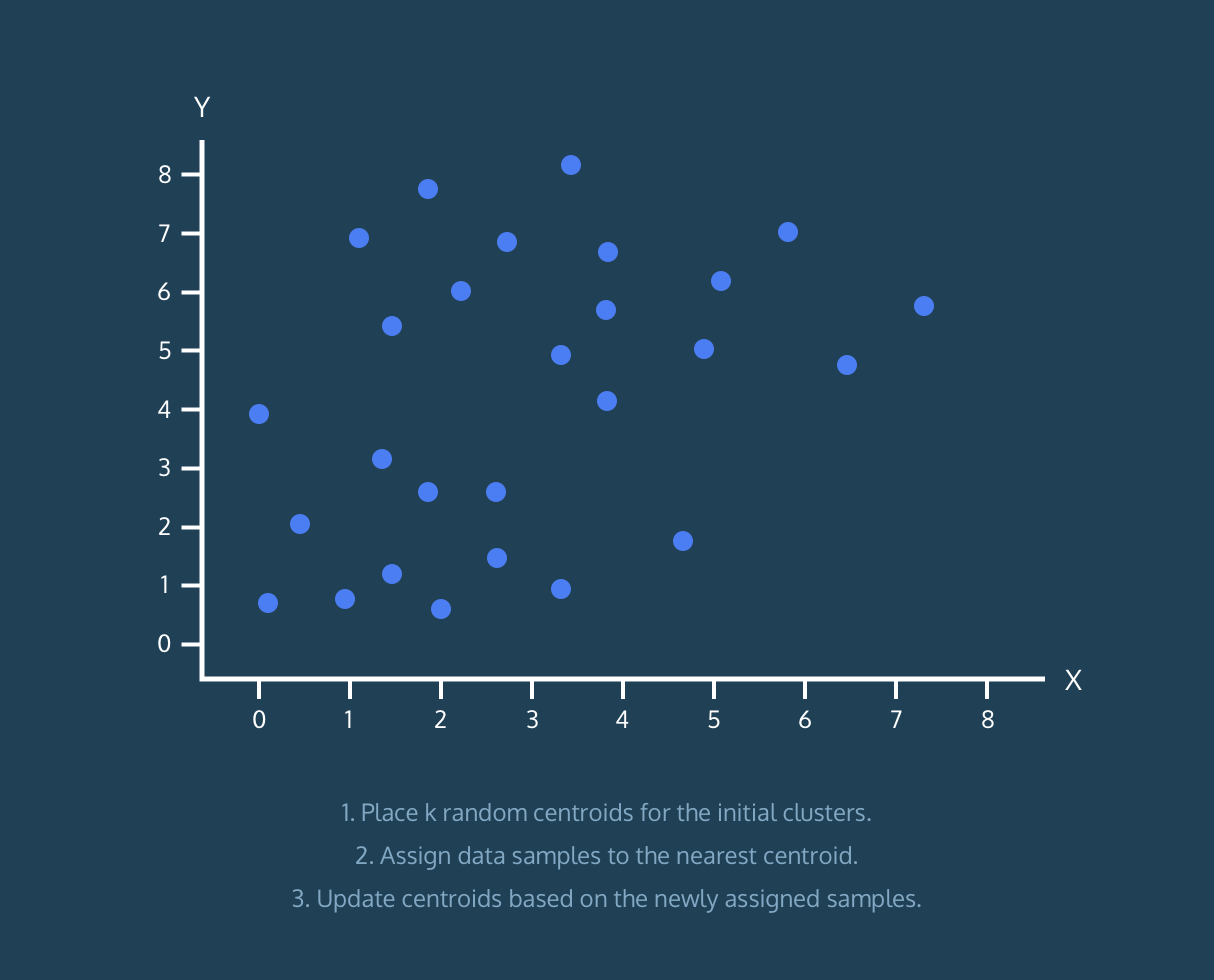

[[Image Source]](https://www.codecademy.com/learn/machine-learning/modules/dspath-clustering/cheatsheet)

## Objective

In this tutorial, we will focus on **K-means clustering** and apply it to the Iris dataset. Our primary aim is to demonstrate the application of clustering in feature classification without relying on predefined labels. We will evaluate the quality of our clustering using a scoring function that aims to minimize the distances between data points and their respective cluster centroids.

The scoring function we aim to minimize is defined as:

$
J(\mathcal{C})=\sum_{i=1}^{k} \sum_{x_j\in \mathcal{C}_i}^{} \|x_j - \mu_i \|^2
$

Here, $k$ represents the number of clusters, $C$ denotes the cluster assignments, $x_j$ represents data points, and $\mu_i$ represents the centroids of the clusters. The goal is to find the clustering that minimizes this score function, indicating well-separated clusters.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math
from sklearn import datasets

In [2]:
iris = datasets.load_iris()
iris_data = pd.DataFrame(data=iris['data'],columns=iris['feature_names'])
iris_data["target"] = iris['target']

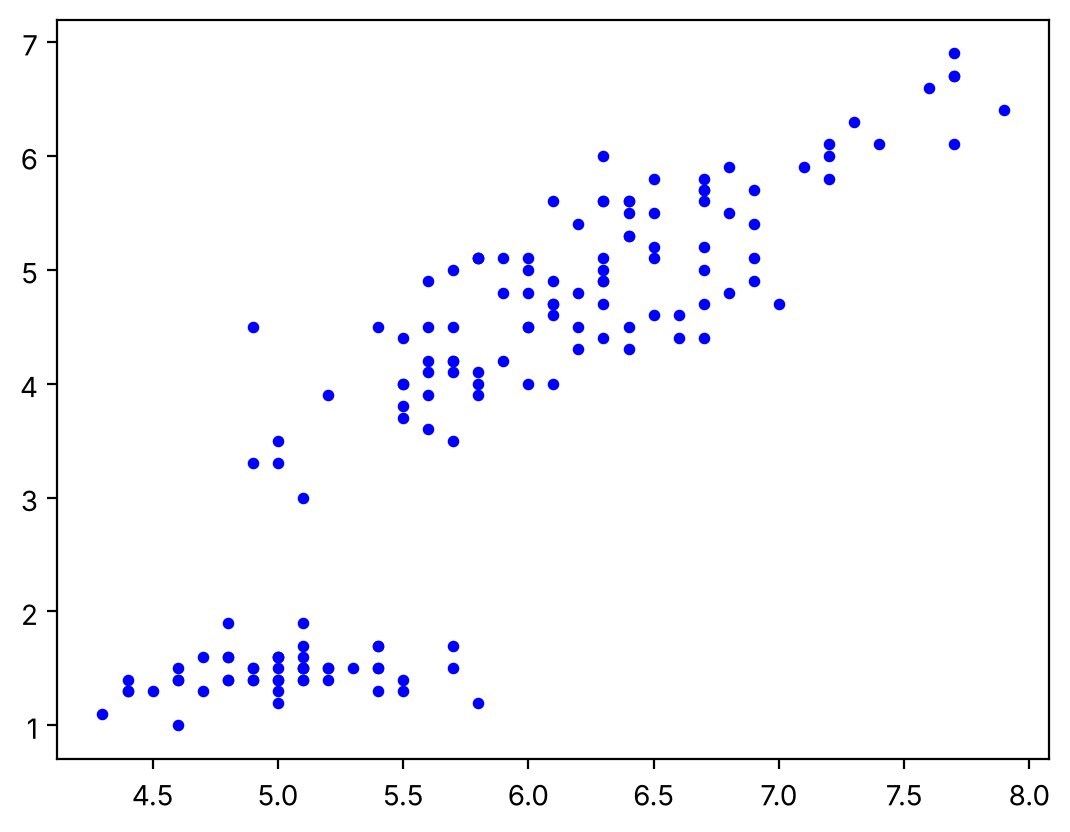

In [3]:
# Here we use the two features sepal length and pertal length
x = iris_data.iloc[:, [0,2]]

# Uncomment the below code for using sepal width and petal width instead
#x = iris_data.iloc[:, [1,3]]

X= x.to_numpy()
plt.scatter(X[:,0], X[:,1], color='b', s=10)
plt.show()

In [4]:
def distance_centers(X,centers):
    """
    Estimating the distance between each data point and the centers using Eulidean distance
    Return the distances and vector that represents class of each data point
    """
    distance = np.array([ np.sum((X-center)**2,axis=1) for center in centers ])
    label = distance.argmin(axis=0)
    return distance, label

In [5]:
def update_centers(X,labels,k):
    """
    Updating the newly formed centers.
    Reurn the new center value
    """
    new_center = np.array([ X[labels == i ].mean(axis=0) for i in range(k)])
    return new_center

In [6]:
def stopping_condition(old_centers,new_centers,current_iter,max_iters):
    """
    If centers are no longer converging or max_iteration is reached stop the algorithm
    """
    if current_iter > max_iters: return True
    return (old_centers == new_centers).all()

In [7]:
def plot_centers(X, centers, labels):
    plt.scatter(X[:,0], X[:,1], s=7, c=labels)
    plt.scatter(centers[:,0], centers[:,1], marker='*', c='r', s=100, label='Cluster centers');
    plt.legend()
    plt.show()

In [8]:
def fit(X,k,max_iters,show_plots):
    """
    Main function that applies Kmeans
    """
    # Intialise centers with random values
    np.random.seed(90)
    centers = X[np.random.choice(X.shape[0], k), :]

    labels = old_centers = None
    iteration = 1
    # Plot intialised centers
    if show_plots == True:
        print('Intialise cluster centers:\n', centers)
        plot_centers(X, centers, labels)

    while not stopping_condition(old_centers,centers,iteration,max_iters):
        distance, labels = distance_centers(X,centers)
        old_centers = centers
        centers = update_centers(X,labels,k)
         # Plot updated centers
        if show_plots == True:
            print('Updated cluster centers:\n', centers)
            plot_centers(X, centers, labels)
        iteration += 1
    # calculate the sum of squared errors (SSE) for Elbow method
    SSE = (np.min(distance, axis=0)**2).sum()
    return centers, labels, SSE

Intialise cluster centers:
 [[6.1 4.6]
 [5.8 5.1]
 [5.8 4.1]]


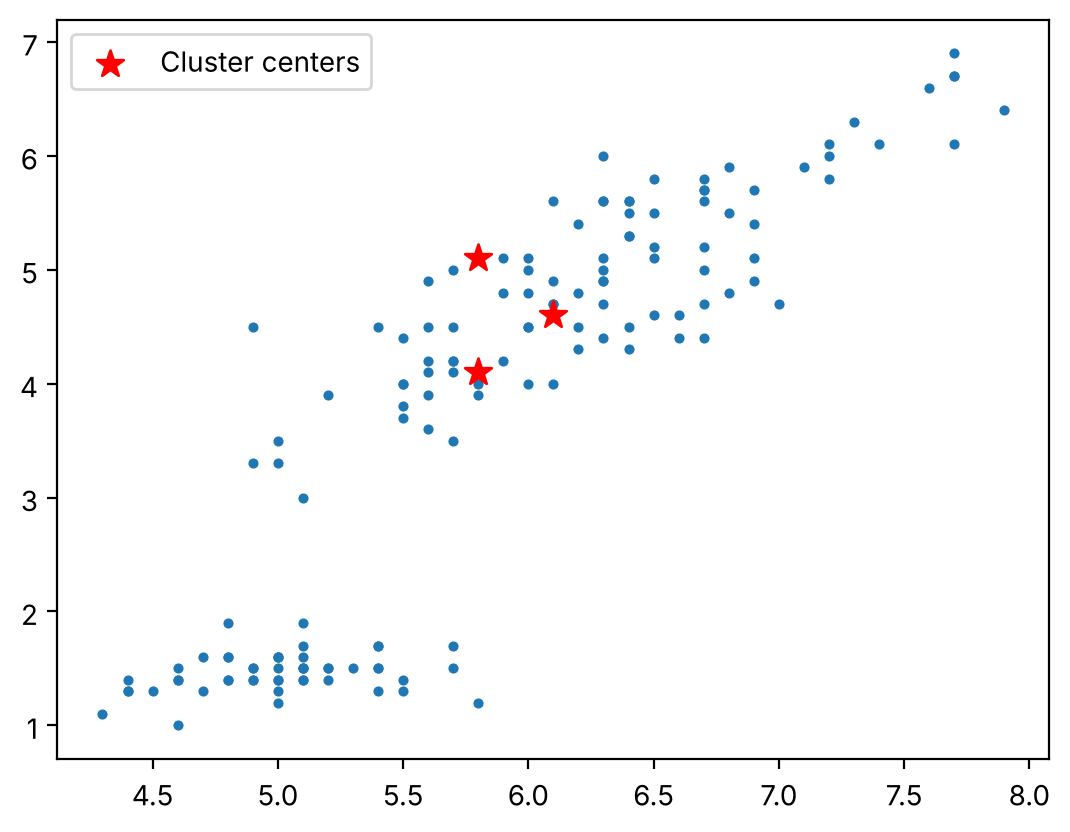

Updated cluster centers:
 [[6.3875     4.725     ]
 [6.64878049 5.68292683]
 [5.18831169 2.33116883]]


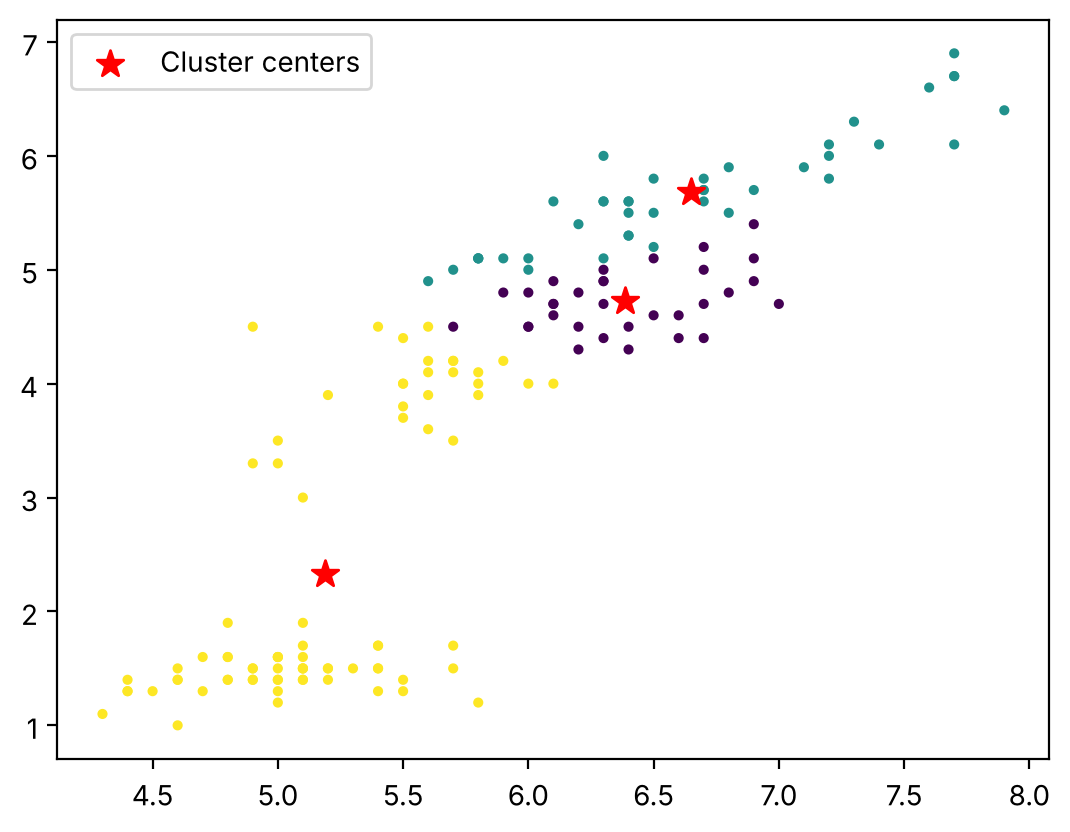

Updated cluster centers:
 [[6.02       4.54      ]
 [6.87352941 5.82352941]
 [5.02857143 1.66607143]]


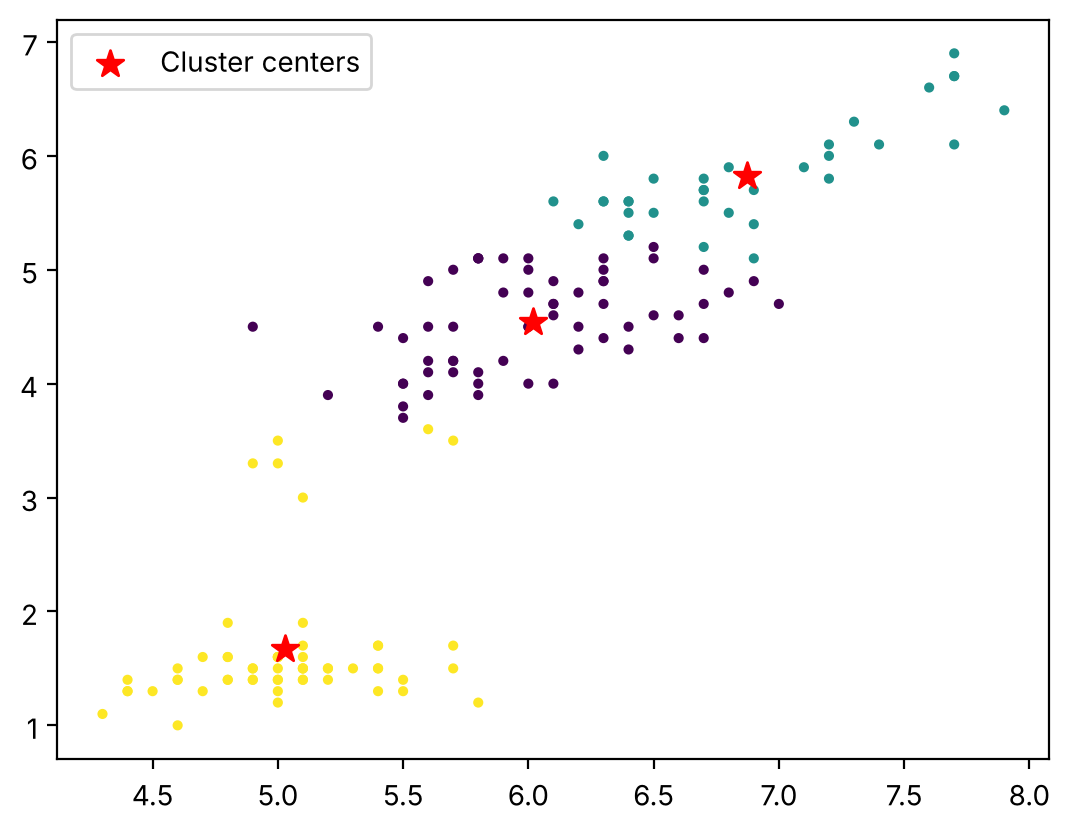

Updated cluster centers:
 [[5.95322581 4.45483871]
 [6.86388889 5.78055556]
 [5.00576923 1.52692308]]


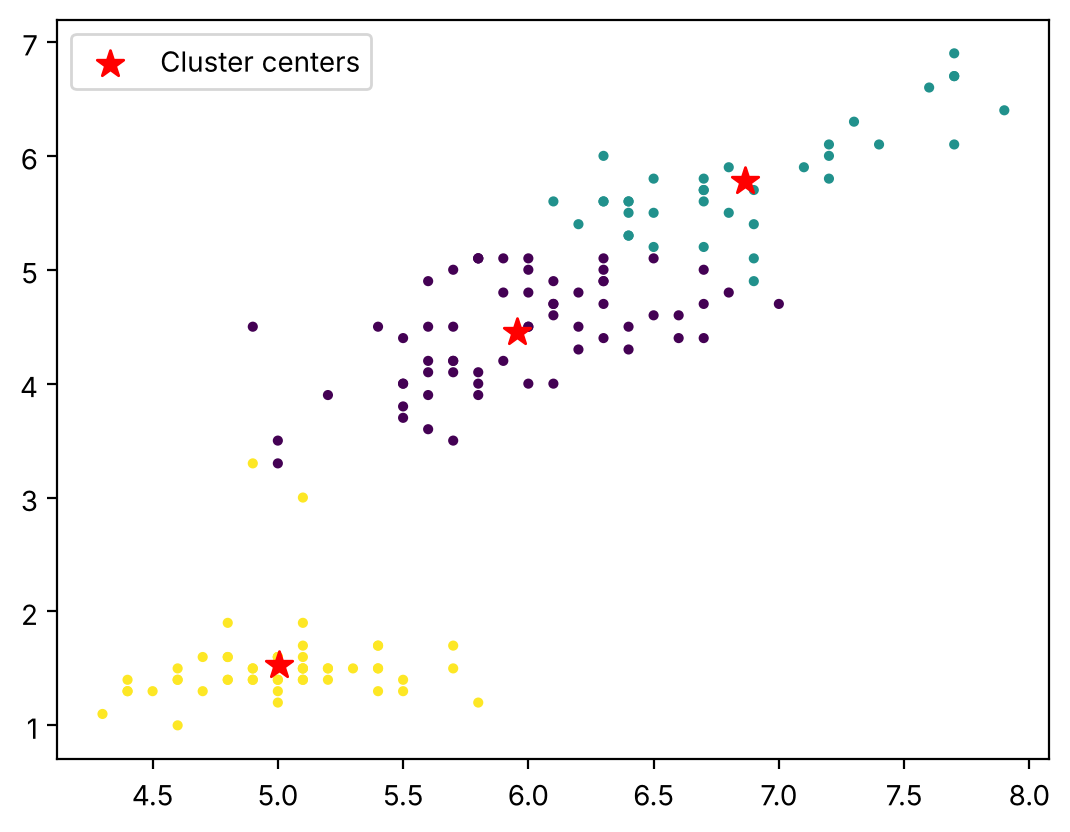

Updated cluster centers:
 [[5.9147541  4.41639344]
 [6.85       5.74210526]
 [5.00784314 1.49215686]]


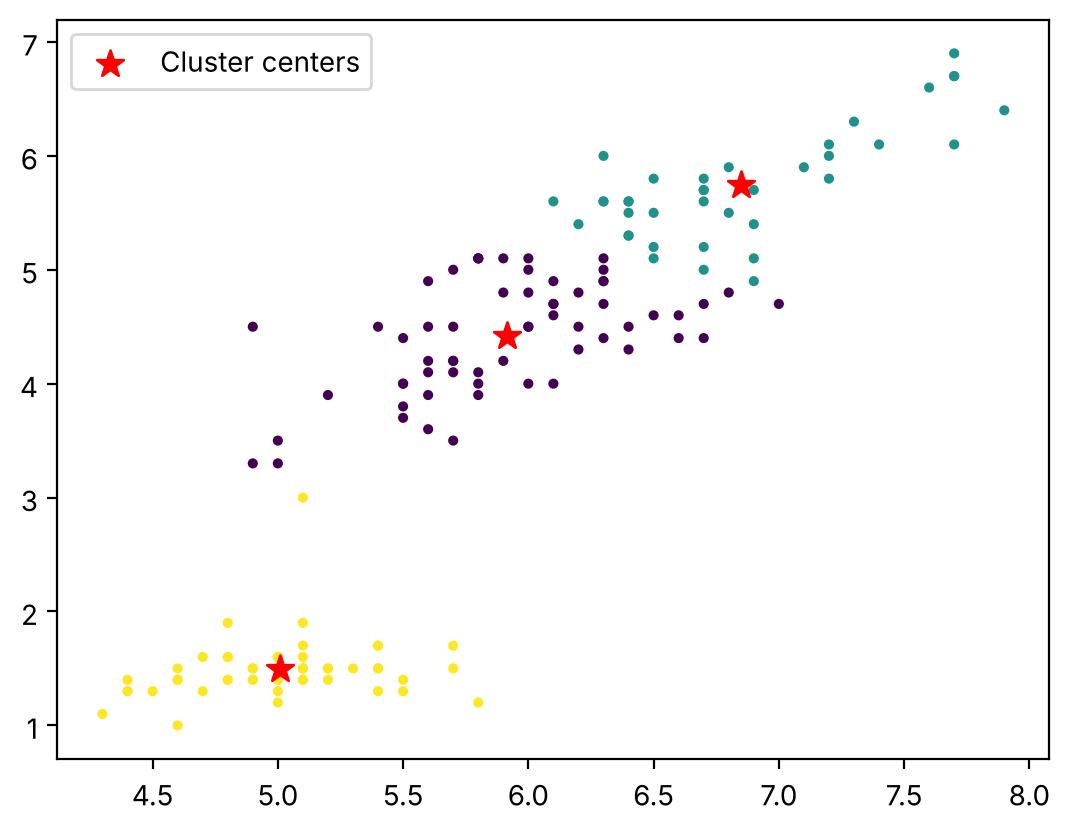

Updated cluster centers:
 [[5.88135593 4.40508475]
 [6.8525     5.6925    ]
 [5.00784314 1.49215686]]


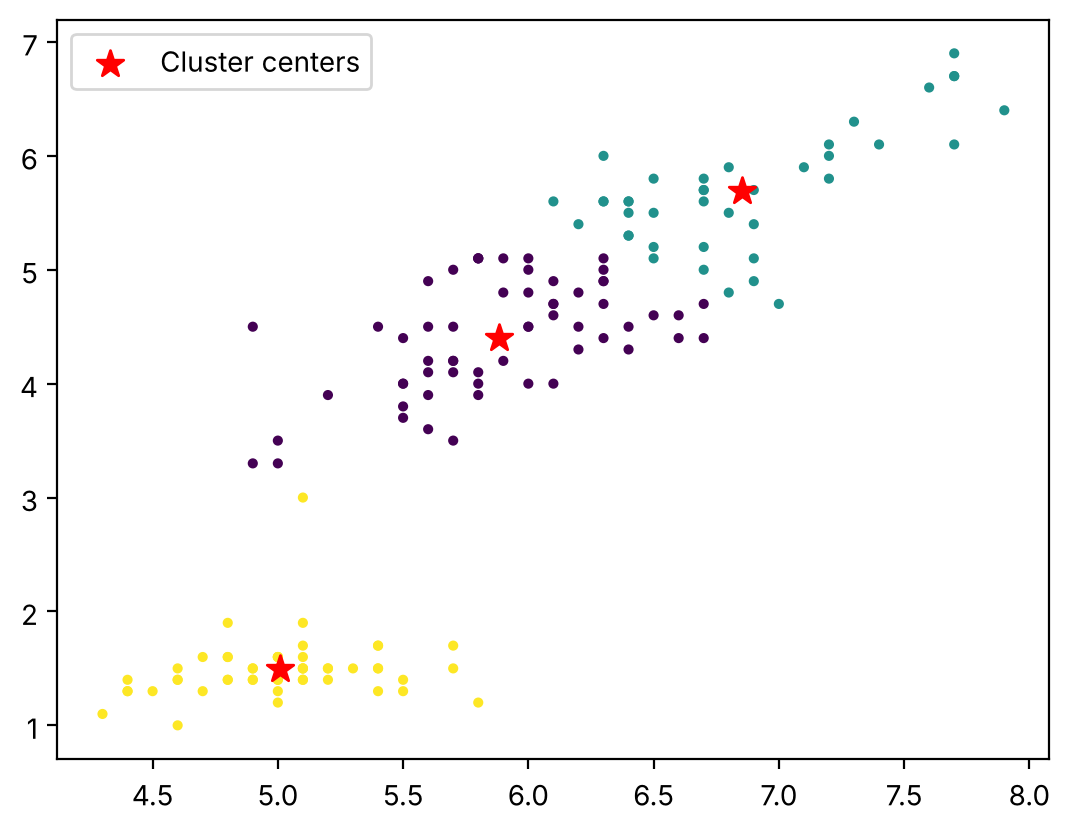

In [9]:
k = 3
show=True
max_iters=5
centers,labels, _ = fit(X,k,max_iters,show)

# Elbow Method

Since Iris-dataset is labelled according to three classes (i.e. Setosa, Virginica and Versicolor), we know in fact that the optimum $k$ (number of centers) should be three as demonstrated in the code above. However, we usually implement unsupervised learning on unlabelled data, which make it difficult to guess the value of $k$. Elbow method can be considered a systematic method to estimate the value of $k$. The idea of the elbow method is to run k-means clustering on the dataset for a range of values of k (say, k from 1 to 8 in the examples above), and for each value of k calculate the sum of squared errors (SSE) as shown in the below cell. Hence, it is not guaranteed that the elbow method will choose the optimum value of $k$, but at least it gives an intuition of an approximate value. For example, if we applied the elbow method on the Iris-dataset, we can see the curve rapidly tapers off after $k=3$ which is our optimum $k$. But according to the same curve, choosing a value $k=2$ is still acceptable.

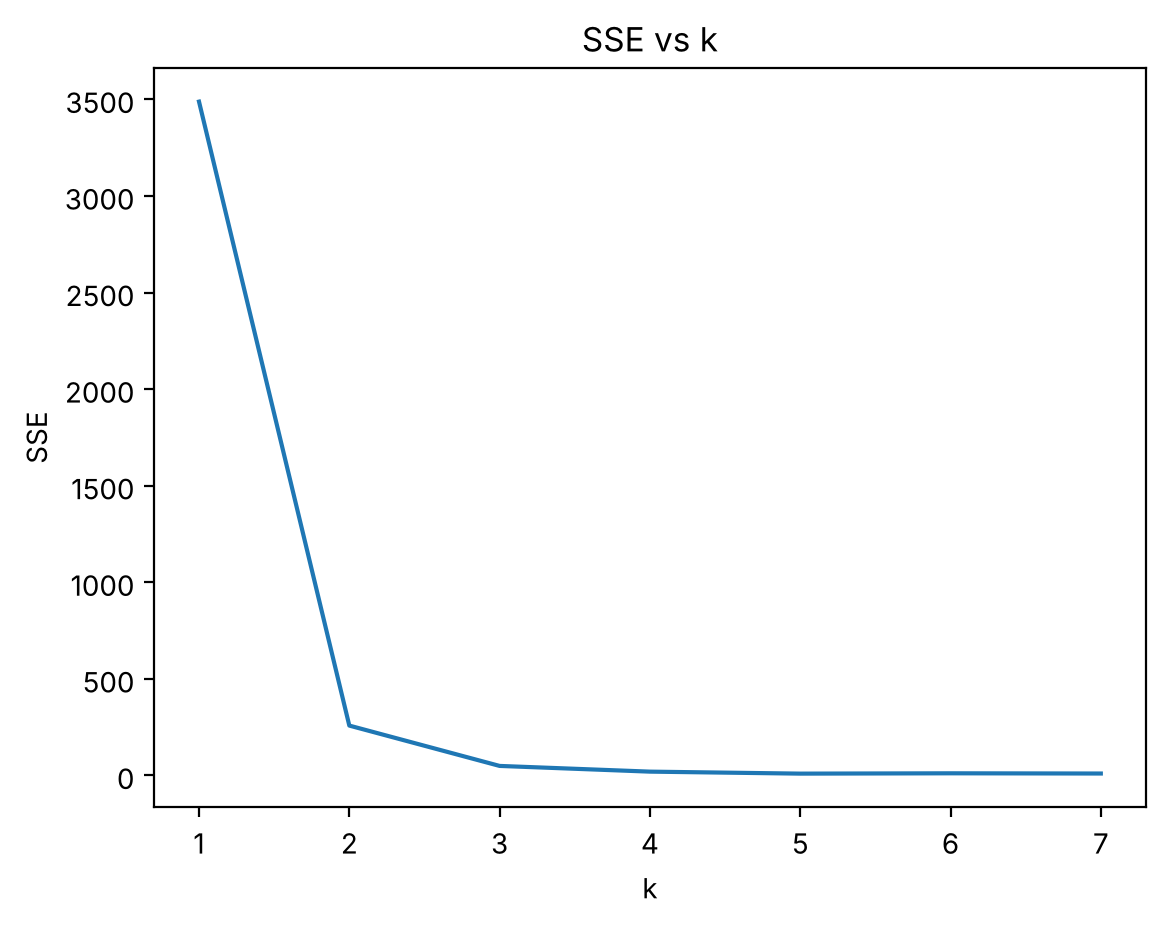

In [10]:
ks = np.arange(1,8)
sse_arr = []
show=False
for k in ks:
    _, _, sse = fit(X, k, max_iters, show)
    sse_arr.append(sse)
plt.plot(ks,sse_arr)
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('SSE vs k')
plt.show()

## Task 1 [40 marks]
Since we have already the labels of this dataset, we can assess the performance of K-means clustering using them. The goal is to estimate the error of the clustering predictions made by K-means.

- Compare the cluster assignments obtained from K-means clustering with the original labels of the dataset by estimating the error or dissimilarity between the two sets of labels. In this task show your code and results obtained.

**Hint:**

It's important to note that the labels generated by K-means clustering may differ from the original dataset's labels. To perform a meaningful evaluation, you can use the dataset's features as a reference point. You have two options:
- Adjust the labels assigned by the K-means algorithm to match the original dataset's labels.
- Alternatively, you can modify the original dataset's labels to align with the clusters formed by K-means.




### Task 1 – Error of our own K-means vs the true labels

K-means numbers its clusters arbitrarily (cluster "0" need not be Setosa), so the cluster IDs must be **matched to the true classes** before counting errors (option 1 in the hint). With k = 3 there are only 3! = 6 possible one-to-one mappings, so every mapping is tried and the one with the fewest mismatches is kept. That mapping is guaranteed to be the best possible, unlike a simple majority vote, which can assign two clusters to the same class.

The tutorial run uses `max_iters = 5`, which may stop before the centres settle. The final model is therefore re-run until convergence (`max_iters = 100`), and both are reported.

In [11]:
# Task 1
from itertools import permutations

true_labels = iris_data["target"].to_numpy()
class_names = iris.target_names

def match_labels(true, pred, k):
    """Find the cluster->class mapping (permutation) that gives the fewest mismatches."""
    best_map, best_err = None, np.inf
    for perm in permutations(range(k)):
        mapped = np.array([perm[c] for c in pred])
        err = np.sum(mapped != true)
        if err < best_err:
            best_err, best_map = err, perm
    mapped = np.array([best_map[c] for c in pred])
    return mapped, best_map, int(best_err)

def confusion(true, pred, k):
    cm = np.zeros((k, k), dtype=int)
    for t, p in zip(true, pred):
        cm[t, p] += 1
    return cm

def report(name, true, pred, k=3):
    mapped, mapping, n_err = match_labels(true, pred, k)
    cm = confusion(true, mapped, k)
    print(f"--- {name} ---")
    print("Cluster -> class mapping:", {c: str(class_names[m]) for c, m in enumerate(mapping)})
    print(f"Misclassified: {n_err} / {len(true)}  ->  error = {100 * n_err / len(true):.2f}%,  accuracy = {100 * (1 - n_err / len(true)):.2f}%")
    print(pd.DataFrame(cm, index=[f"true {c}" for c in class_names], columns=[f"pred {c}" for c in class_names]))
    return mapped, mapping, n_err

In [12]:
# Task 1 (continued) - tutorial run (max_iters = 5) and converged run (max_iters = 100)
k = 3
centers_5, labels_5, _ = fit(X, k, 5, False)
centers_own, labels_own, _ = fit(X, k, 100, False)
print("Centres after max_iters=5  :\n", np.round(centers_5, 4))
print("Centres after convergence  :\n", np.round(centers_own, 4))
print("Same assignments?", np.array_equal(labels_5, labels_own), "\n")

mapped_5, _, err_5 = report("Own K-means, max_iters = 5", true_labels, labels_5)
print()
mapped_own, map_own, err_own = report("Own K-means, converged", true_labels, labels_own)

Centres after max_iters=5  :
 [[5.8814 4.4051]
 [6.8525 5.6925]
 [5.0078 1.4922]]
Centres after convergence  :
 [[5.8741 4.3931]
 [6.839  5.678 ]
 [5.0078 1.4922]]
Same assignments? False 

--- Own K-means, max_iters = 5 ---
Cluster -> class mapping: {0: 'versicolor', 1: 'virginica', 2: 'setosa'}
Misclassified: 19 / 150  ->  error = 12.67%,  accuracy = 87.33%
                 pred setosa  pred versicolor  pred virginica
true setosa               50                0               0
true versicolor            1               45               4
true virginica             0               14              36

--- Own K-means, converged ---
Cluster -> class mapping: {0: 'versicolor', 1: 'virginica', 2: 'setosa'}
Misclassified: 18 / 150  ->  error = 12.00%,  accuracy = 88.00%
                 pred setosa  pred versicolor  pred virginica
true setosa               50                0               0
true versicolor            1               45               4
true virginica             0       

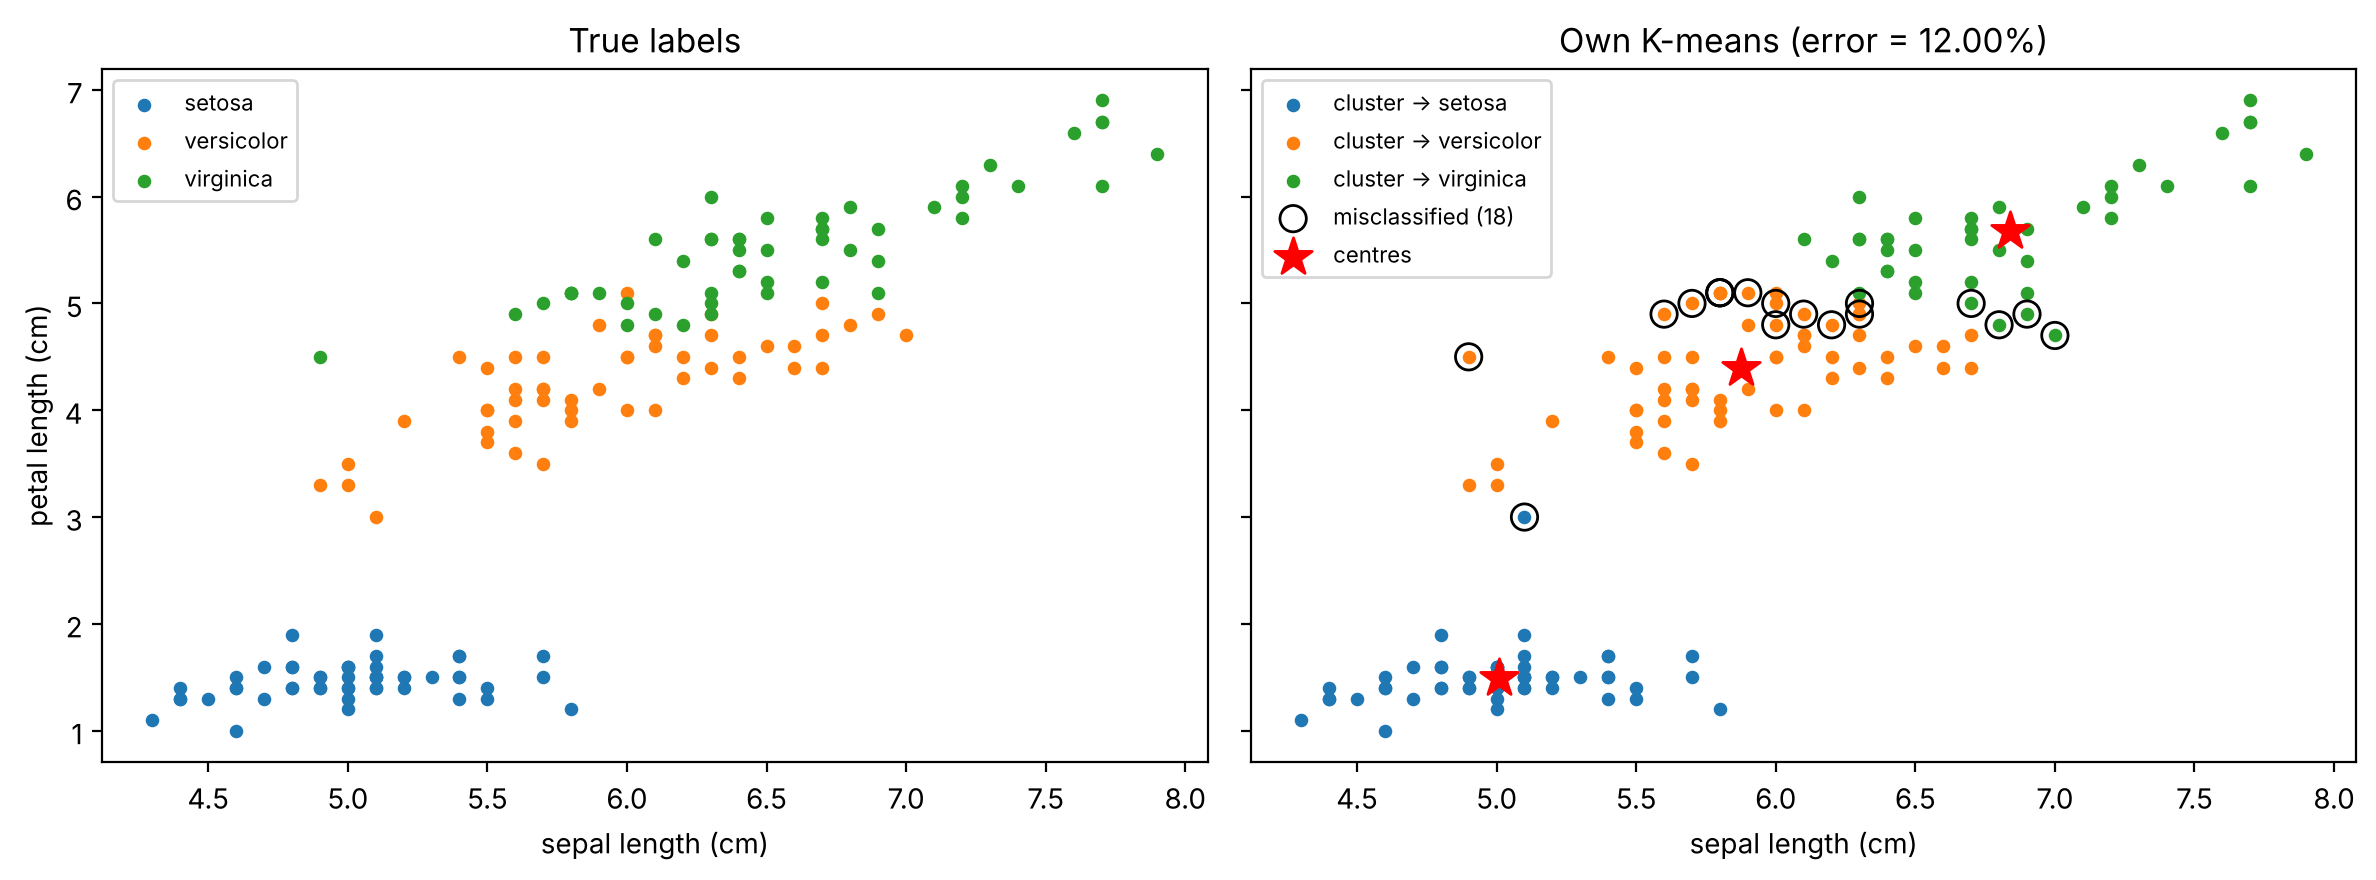

In [13]:
# Task 1 (continued) - visual comparison: true labels vs K-means clusters, errors marked
def compare_plot(X, true, mapped, centers, mapping, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for c in range(3):
        axes[0].scatter(X[true == c, 0], X[true == c, 1], s=15, label=class_names[c])
        axes[1].scatter(X[mapped == c, 0], X[mapped == c, 1], s=15, label=f"cluster -> {class_names[c]}")
    wrong = mapped != true
    axes[1].scatter(X[wrong, 0], X[wrong, 1], s=90, facecolors='none', edgecolors='k', label=f"misclassified ({wrong.sum()})")
    if centers is not None:
        axes[1].scatter(centers[:, 0], centers[:, 1], marker='*', c='r', s=200, label='centres')
    axes[0].set_title("True labels"); axes[1].set_title(title)
    for ax in axes:
        ax.set_xlabel(iris.feature_names[0]); ax.legend(fontsize=8)
    axes[0].set_ylabel(iris.feature_names[2])
    plt.tight_layout(); plt.show()

compare_plot(X, true_labels, mapped_own, centers_own, map_own, f"Own K-means (error = {100 * err_own / 150:.2f}%)")

**Task 1 notes.**
* After matching cluster IDs to classes, the converged K-means misclassifies **18 / 150 points (12.0% error, 88.0% accuracy)**. The tutorial setting `max_iters = 5` stops one step before convergence and gives 19 errors (12.7%).
* **Setosa is recovered almost perfectly.** All 50 Setosa flowers fall in one cluster, and only 1 Versicolor point is pulled into it, because Setosa is far away from the other two species in sepal length / petal length.
* **Nearly all errors are between Versicolor and Virginica**: 13 Virginica are put in the Versicolor cluster, and 4 Versicolor in the Virginica cluster. The two species overlap in these features. K-means draws straight boundaries halfway between centres and assumes round clusters of similar size, so points in the overlap region go to whichever centre is closer, regardless of their real species.
* The clustering never saw the labels. They are used only afterwards to measure how well the natural groups line up with the species.
* *Side note on the tutorial code:* `distance_centers` already returns **squared** distances, and `fit` squares them again when computing the SSE, so the elbow plot shows $\sum d^4$ rather than $\sum d^2$. The elbow shape is similar, but the y-axis values are not the true SSE of the scoring function $J$.

# Scikit-learn Implementation

If you're looking to apply clustering to your data using Python, scikit-learn provides a convenient and user-friendly way to do so. There are multiple algorithms used in clustering, you can explore them [here](https://scikit-learn.org/stable/modules/clustering.html)

In order to implement K-means clustering using scikit-learn, you will need to import the following:

```python
from sklearn.cluster import KMeans
```

You can initialise the algorithm with various parameters:
> More information can be found [here](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html#sklearn.cluster.KMeans)

In order to implement agglomerative hierarchical clustering using scikit-learn, you will need to import the following:

```python
from sklearn.cluster import AgglomerativeClustering
```
You can initialise the algorithm with various parameters:
> More information can be found [here](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html#sklearn.cluster.AgglomerativeClustering)

## Task 2 [30 marks]

In this task, we will replicate the process carried out in Task 1, but this time, we'll utilize the scikit-learn library to implement K-means clustering. The objective remains the same: to estimate the error or dissimilarity resulting from the clustering and subsequently compare the performance of both approaches.

**Step 1: Implement K-means with scikit-learn**

- Begin by applying K-means clustering to the dataset using the scikit-learn package.
- Obtain the cluster assignments for the data points.

**Step 2: Assessing the Clustering Outcome**

- Next, evaluate the cluster assignments obtained through scikit-learn's K-means clustering.
- Estimate and analyze the error or discrepancy between these cluster assignments and the original dataset labels.

**Step 3: Performance Comparison**

- Compare the results achieved through the scikit-learn implementation with those from Task 1 where you implemented K-means clustering without external libraries in terms of the cluster centers obtained and the error achieved.


scikit-learn centres:
 [[5.8741 4.3931]
 [5.0078 1.4922]
 [6.839  5.678 ]]
Iterations: 8 | inertia (true SSE, sum of squared distances): 53.81
--- scikit-learn K-means ---
Cluster -> class mapping: {0: 'versicolor', 1: 'setosa', 2: 'virginica'}
Misclassified: 18 / 150  ->  error = 12.00%,  accuracy = 88.00%
                 pred setosa  pred versicolor  pred virginica
true setosa               50                0               0
true versicolor            1               45               4
true virginica             0               13              37


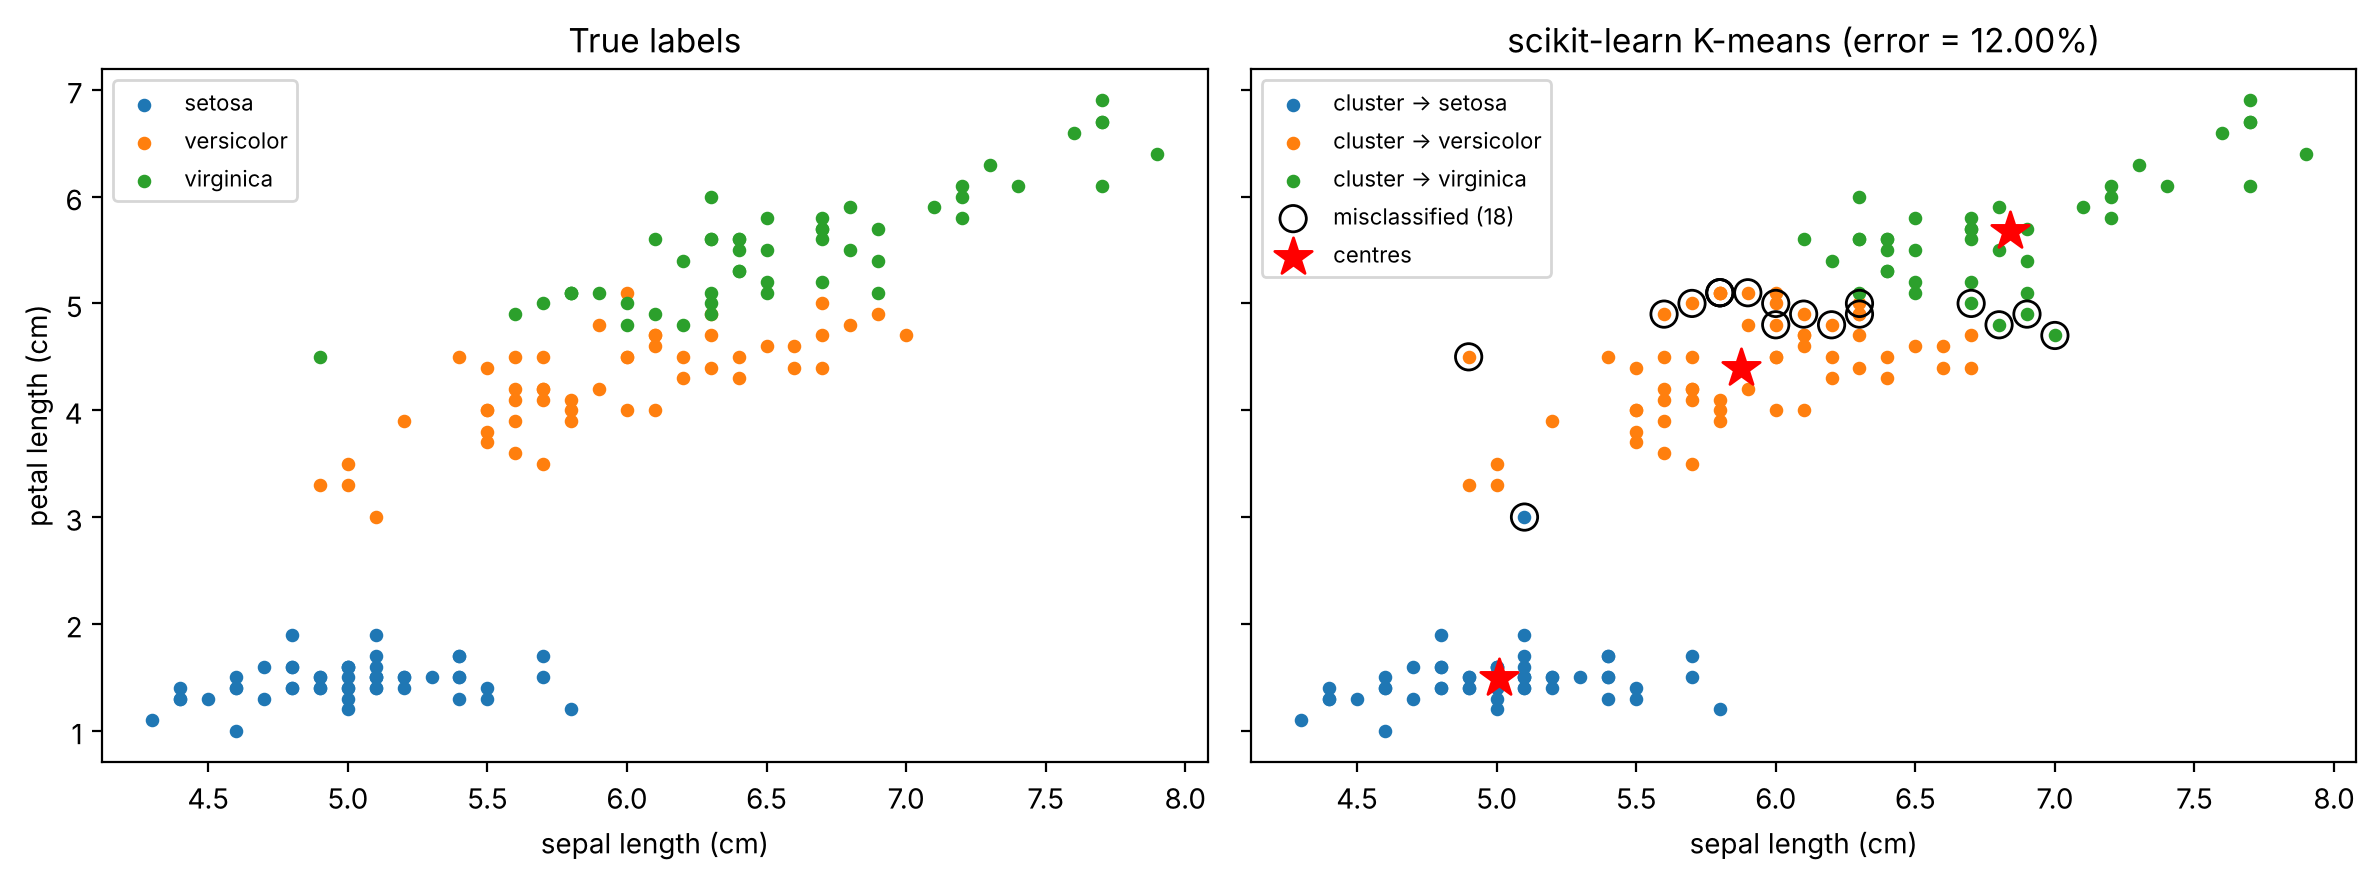

In [14]:
# Task 2 - Step 1: K-means with scikit-learn
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
labels_sk = kmeans.fit_predict(X)
centers_sk = kmeans.cluster_centers_
print("scikit-learn centres:\n", np.round(centers_sk, 4))
print("Iterations:", kmeans.n_iter_, "| inertia (true SSE, sum of squared distances):", round(kmeans.inertia_, 4))

# Step 2: error vs the true labels
mapped_sk, map_sk, err_sk = report("scikit-learn K-means", true_labels, labels_sk)
compare_plot(X, true_labels, mapped_sk, centers_sk, map_sk, f"scikit-learn K-means (error = {100 * err_sk / 150:.2f}%)")

In [15]:
# Task 2 - Step 3: comparison with our implementation (Task 1)
# Put both sets of centres in the same order (by the class each cluster is mapped to)
def centres_by_class(centers, mapping):
    out = np.zeros_like(centers)
    for cluster, cls in enumerate(mapping):
        out[cls] = centers[cluster]
    return out

c_own = centres_by_class(centers_own, map_own)
c_sk = centres_by_class(centers_sk, map_sk)

def sse(X, labels, centers):
    return float(sum(np.sum((X[labels == i] - centers[i]) ** 2) for i in range(len(centers))))

comparison = pd.DataFrame({
    "class": class_names,
    "own centre (sepal len)": c_own[:, 0], "own centre (petal len)": c_own[:, 1],
    "sklearn centre (sepal len)": c_sk[:, 0], "sklearn centre (petal len)": c_sk[:, 1],
    "|difference|": np.linalg.norm(c_own - c_sk, axis=1)}).round(4)
display(comparison)

summary = pd.DataFrame({
    "method": ["Own K-means (max_iters=5)", "Own K-means (converged)", "scikit-learn KMeans"],
    "misclassified": [err_5, err_own, err_sk],
    "error (%)": [100 * err_5 / 150, 100 * err_own / 150, 100 * err_sk / 150],
    "SSE  J(C)": [sse(X, labels_5, centers_5), sse(X, labels_own, centers_own), sse(X, labels_sk, centers_sk)]}).round(4)
display(summary)
print("Identical assignments (after mapping)?", np.array_equal(mapped_own, mapped_sk))

,class,own centre (sepal len),own centre (petal len),sklearn centre (sepal len),sklearn centre (petal len),|difference|
0,setosa,5.0078,1.4922,5.0078,1.4922,0.0
1,versicolor,5.8741,4.3931,5.8741,4.3931,0.0
2,virginica,6.8390,5.6780,6.8390,5.6780,0.0


,method,misclassified,error (%),SSE J(C)
0,Own K-means (max_iters=5),19,12.6667,53.8392
1,Own K-means (converged),18,12.0000,53.8100
2,scikit-learn KMeans,18,12.0000,53.8100


Identical assignments (after mapping)? True


**Task 2 notes.**
* scikit-learn's `KMeans` runs the same Lloyd algorithm (assign to nearest centre → recompute means). By default it also uses **k-means++ initialisation** and **10 restarts** (`n_init=10`), keeping the run with the lowest SSE (`inertia_`). Our version starts from 3 randomly chosen data points with a fixed seed and runs once.
* On this dataset both reach **exactly the same solution**. The centres agree to 4 decimal places (Setosa (5.008, 1.492), Versicolor (5.874, 4.393), Virginica (6.839, 5.678)), the assignments are identical, and both have **18 errors (12.0%)** and SSE $J = 53.81$. scikit-learn converged in 8 iterations. The three clusters are well defined, so our single random start was enough to find the same minimum.
* With an unlucky initialisation, for example two starting centres inside the Setosa cloud, our single-run version could get stuck in a worse local minimum (higher SSE, much higher error). The multiple restarts and smarter initialisation in scikit-learn guard against that. That robustness is the practical advantage of the library version.
* The remaining error is **not an algorithm problem**. It comes from the Versicolor/Virginica overlap in these two features, so no K-means implementation can remove it.

## Task 3 [30 marks]

- Write a code using agglomerative hierarchical clustering for the same dataset and estimate the error of your predictions. (You can use scikitlearn package for this task)

In this task, your assignment is to implement Agglomerative Hierarchical Clustering on the given dataset. You will then compare the cluster labels generated by this clustering method with the true labels in order to calculate and analyse the error.

**Step 1: Implement Agglomerative Hierarchical Clustering**

- Your first task is to write code to apply Agglomerative Hierarchical Clustering to the dataset.

**Step 2: Compare Predicted Labels with True Labels**

- Once you have the cluster assignments from the Agglomerative Hierarchical Clustering, compare them with the true labels provided in the dataset.
- Calculate the error between the predicted cluster labels and the actual labels.



> You are allowed to use scikit-learn package in this task by importing the following:

```python
from sklearn.cluster import AgglomerativeClustering
```



--- Agglomerative (ward linkage) ---
Cluster -> class mapping: {0: 'virginica', 1: 'setosa', 2: 'versicolor'}
Misclassified: 24 / 150  ->  error = 16.00%,  accuracy = 84.00%
                 pred setosa  pred versicolor  pred virginica
true setosa               50                0               0
true versicolor            0               27              23
true virginica             0                1              49


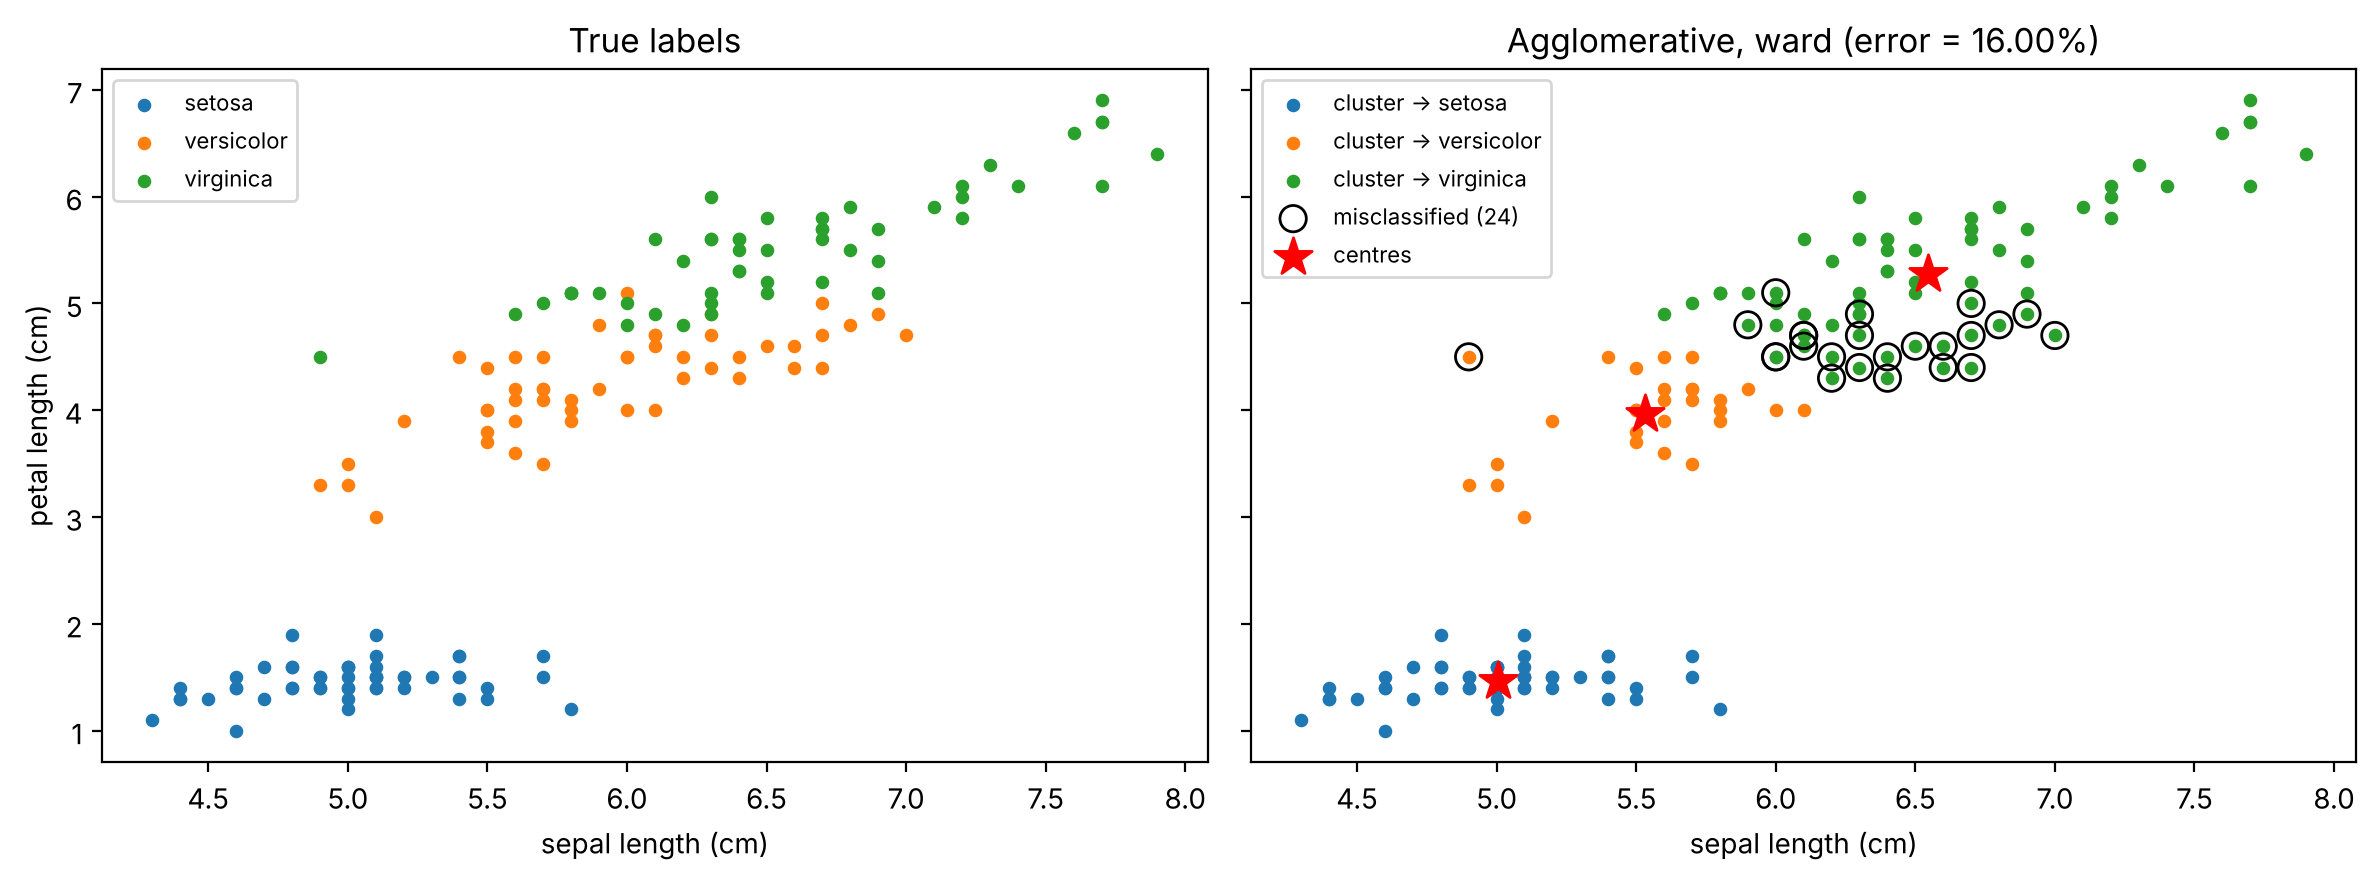

In [16]:
# Task 3 - Step 1: agglomerative hierarchical clustering
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=3, linkage='ward')   # ward = merge clusters that least increase SSE
labels_agg = agg.fit_predict(X)

# Step 2: compare with the true labels
mapped_agg, map_agg, err_agg = report("Agglomerative (ward linkage)", true_labels, labels_agg)
centers_agg = np.array([X[labels_agg == i].mean(axis=0) for i in range(3)])   # cluster means, for plotting only
compare_plot(X, true_labels, mapped_agg, centers_agg, map_agg, f"Agglomerative, ward (error = {100 * err_agg / 150:.2f}%)")

,method,misclassified,error (%),cluster sizes
0,Own K-means (converged),18,12.00,"[58, 51, 41]"
1,scikit-learn KMeans,18,12.00,"[58, 51, 41]"
2,Agglomerative (ward),24,16.00,"[72, 50, 28]"
3,Agglomerative (complete),16,10.67,"[66, 50, 34]"
4,Agglomerative (average),38,25.33,"[88, 50, 12]"
5,Agglomerative (single),49,32.67,"[99, 50, 1]"


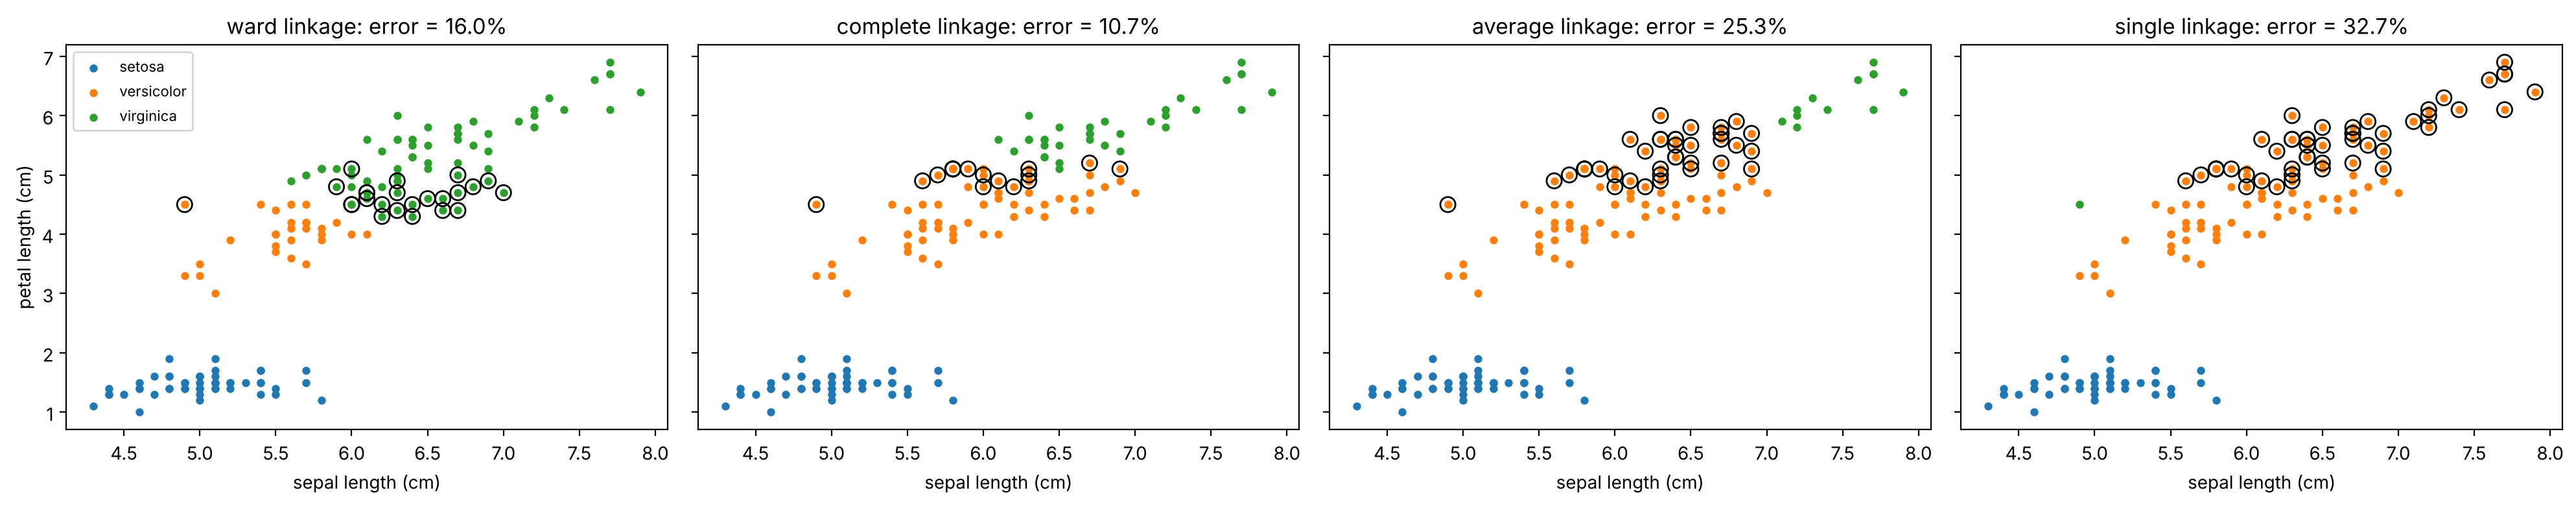

In [17]:
# Task 3 (continued) - effect of the linkage criterion, and overall comparison
rows = []
for linkage in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=3, linkage=linkage).fit_predict(X)
    _, _, e = match_labels(true_labels, lab, 3)
    sizes = np.bincount(lab, minlength=3)
    rows.append([f"Agglomerative ({linkage})", e, 100 * e / 150, sorted(sizes.tolist(), reverse=True)])
rows.insert(0, ["scikit-learn KMeans", err_sk, 100 * err_sk / 150, sorted(np.bincount(labels_sk).tolist(), reverse=True)])
rows.insert(0, ["Own K-means (converged)", err_own, 100 * err_own / 150, sorted(np.bincount(labels_own).tolist(), reverse=True)])
overall = pd.DataFrame(rows, columns=["method", "misclassified", "error (%)", "cluster sizes"]).round(2)
display(overall)

fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, linkage in zip(axes, ['ward', 'complete', 'average', 'single']):
    lab = AgglomerativeClustering(n_clusters=3, linkage=linkage).fit_predict(X)
    mapped, _, e = match_labels(true_labels, lab, 3)
    for c in range(3):
        ax.scatter(X[mapped == c, 0], X[mapped == c, 1], s=12, label=class_names[c])
    ax.scatter(X[mapped != true_labels, 0], X[mapped != true_labels, 1], s=70, facecolors='none', edgecolors='k')
    ax.set_title(f"{linkage} linkage: error = {100 * e / 150:.1f}%"); ax.set_xlabel(iris.feature_names[0])
axes[0].set_ylabel(iris.feature_names[2]); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Task 3 notes.**
* Agglomerative clustering starts with every point as its own cluster and repeatedly merges the two closest clusters until 3 are left. The **linkage** defines "closest".
* **Ward linkage (the default): 24 / 150 errors (16.0%).** Setosa is again separated perfectly. But Ward puts the Versicolor/Virginica split in a different place from K-means: 23 Versicolor are grouped with Virginica, which gives cluster sizes of 72 / 50 / 28. Merges are final (a point can never move once merged), so an early merge in the overlap region cannot be undone later, whereas K-means reassigns points at every iteration. So Ward is worse than K-means (12.0%) here, even though both try to keep the within-cluster SSE low.
* **Linkage matters a lot:**
  * **Complete** linkage (distance between the farthest points) gives the best result of all methods, **10.67% error**, because it favours compact clusters.
  * **Average** linkage gives 25.3%.
  * **Single** linkage (distance between the closest points) gives 32.7%. It suffers from "chaining": the Versicolor and Virginica clouds touch, so they are merged into one cluster of 99 points, and the third "cluster" is a single outlier.
* **Conclusion.** Every method finds Setosa. The remaining error depends on how each method splits the overlapping Versicolor/Virginica region. With these two features: complete linkage 10.7% < K-means 12.0% < Ward 16.0% < average 25.3% < single 32.7%. No method can get to 0%, because the two species genuinely overlap in sepal length and petal length.